### Step 1：繪製 4 月每日最低價與平均價走勢圖

讀取 CSV、篩選 4 月資料，依出發日期算每日最低價與平均價，畫成折線圖，並標示週末與清明連假（4/3～4/6）底色。

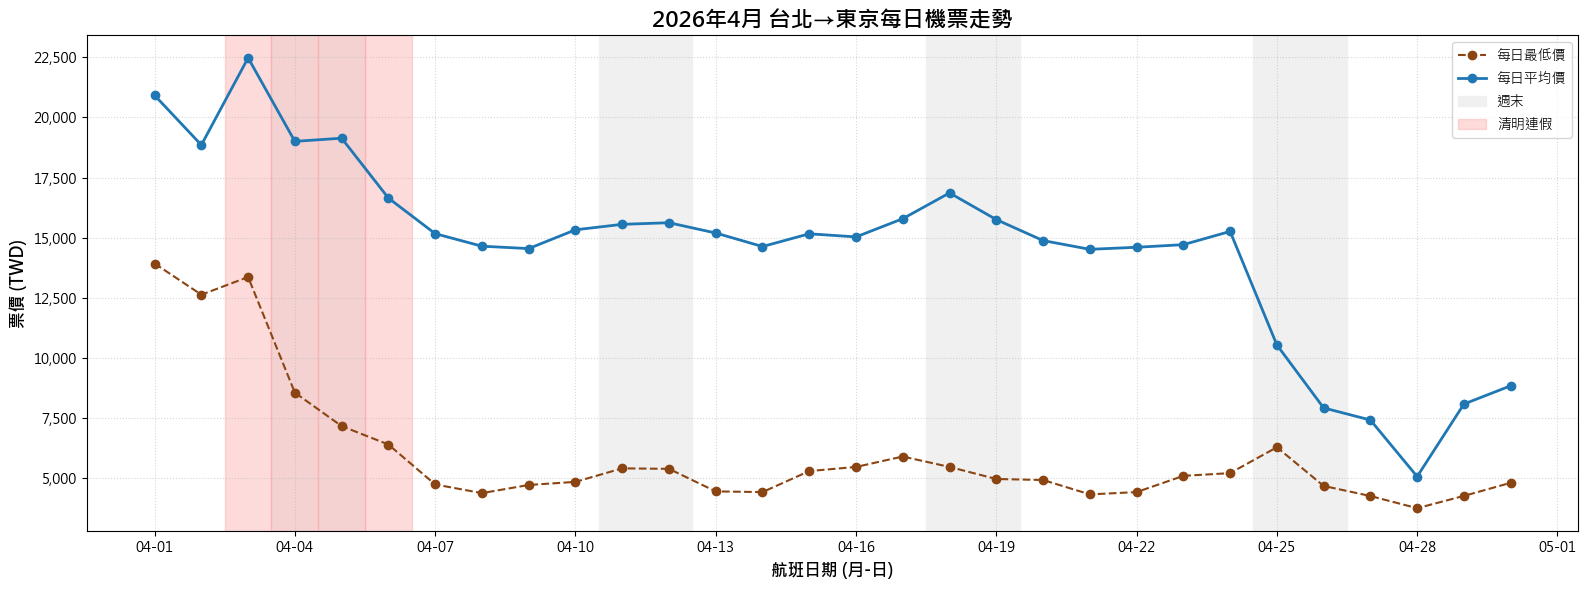

In [3]:
#2026年4月 台北→東京每日機票走勢

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

# 環境設定
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei']
plt.rcParams['axes.unicode_minus'] = False

# 資料處理
df = pd.read_csv('台北_東京_經濟艙直飛.csv')
df['date'] = pd.to_datetime(df['date'])
df_apr = df[df['date'].dt.month == 4].copy()
df_daily = df_apr.groupby('date')['ticket_price'].agg(['min', 'mean']).reset_index()

# 建立畫布
plt.figure(figsize=(16, 6))

# 繪製底色 (週末與連假)
all_days = pd.date_range(start='2026-04-01', end='2026-04-30')
for d in all_days:
    # 週末底色 (週六、日)
    if d.dayofweek >= 5:
        plt.axvspan(d - pd.Timedelta(days=0.5), d + pd.Timedelta(days=0.5), 
                    color='#F0F0F0', alpha=1.0, zorder=0)
    # 清明連假底色 (4/3 ~ 4/6)
    if pd.to_datetime('2026-04-03') <= d <= pd.to_datetime('2026-04-06'):
        plt.axvspan(d - pd.Timedelta(days=0.5), d + pd.Timedelta(days=0.5), 
                    color='#FCA5A5', alpha=0.4, zorder=1)

# 繪製折線
plt.plot(df_daily['date'], df_daily['min'], color='#8B4513', marker='o', linestyle='--', label='每日最低價', zorder=3)
plt.plot(df_daily['date'], df_daily['mean'], color='#1f77b4', marker='o', linestyle='-', linewidth=2, label='每日平均價', zorder=3)

# 設定座標軸與標題
plt.title('2026年4月 台北→東京每日機票走勢', fontsize=16, fontweight='bold')
plt.xlabel('航班日期 (月-日)', fontsize=12, fontweight='bold')
plt.ylabel('票價 (TWD)', fontsize=12, fontweight='bold')

# X 軸時間格式處理
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xticks(rotation=0)

# Y 軸格式處理
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: format(int(x), ',')))

# 格線與圖例
plt.grid(True, linestyle=':', alpha=0.5, zorder=2)

# 自定義圖例內容
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(mpatches.Patch(color='#F0F0F0', label='週末'))
handles.append(mpatches.Patch(color='#FCA5A5', alpha=0.4, label='清明連假'))
plt.legend(handles=handles, loc='upper right')

plt.tight_layout()
plt.savefig('2026年4月_每日機票走勢.png', dpi=300)
plt.show()

### Step 2：繪製各星期平均票價長條圖

將 4 月資料依星期幾分組，計算各星期平均票價，畫成長條圖並標註金額。

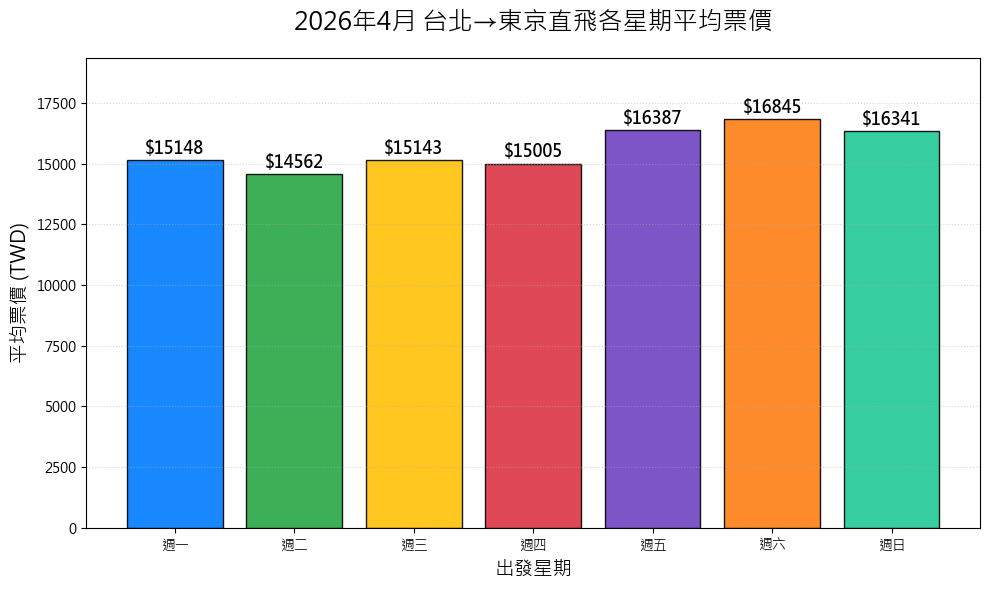

In [4]:
# 2026年4月 台北→東京直飛各星期平均票價

import pandas as pd
import matplotlib.pyplot as plt

# 基礎設定與環境
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

# 讀取資料並篩選 4 月份
df = pd.read_csv('台北_東京_經濟艙直飛.csv')
df['date'] = pd.to_datetime(df['date'])
df_apr = df[df['date'].dt.month == 4].copy()

# 計算星期（0=Mon, 6=Sun）
df_apr['weekday'] = df_apr['date'].dt.dayofweek
weekday_avg = df_apr.groupby('weekday')['ticket_price'].mean()
week_labels = ['週一', '週二', '週三', '週四', '週五', '週六', '週日']

# 開始繪圖
plt.figure(figsize=(10, 6))

# 配色設定
vivid_colors = ['#007bff', '#28a745', '#ffc107', '#dc3545', '#6f42c1', '#fd7e14', '#20c997']

# 繪製長條圖
bars = plt.bar(week_labels, weekday_avg, color=vivid_colors, edgecolor='black', alpha=0.9)

# 在長條上方標註金額
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 100, 
             '$%d' % int(height), ha='center', va='bottom', fontsize=12, fontweight='bold')

# 設定標題與座標軸標籤
plt.title('2026年4月 台北→東京直飛各星期平均票價', fontsize=18, pad=20)
plt.xlabel('出發星期', fontsize=14)  
plt.ylabel('平均票價 (TWD)', fontsize=14)

plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.ylim(0, max(weekday_avg) * 1.15)

# 存檔與顯示
plt.tight_layout()
plt.savefig('2026年4月_各星期平均票價.png', dpi=300, bbox_inches='tight')
plt.show()

### Step 3：驗證每日價格與樣本數

依出發日期彙總最低價、平均價與筆數，檢查：
- 4/3（清明首日）的價格與筆數
- 4/7～4/24 平日與週末的平均價區間
- 4/25 之後每日筆數（樣本偏少）

In [5]:
daily = df_apr.groupby('date')['ticket_price'].agg(['min', 'mean', 'count'])
print(daily.loc['2026-04-03'])                       # 4/3 平均價
mid = daily.loc['2026-04-07':'2026-04-24'].copy()
mid['weekend'] = mid.index.dayofweek >= 5
print(mid.groupby('weekend')['mean'].agg(['min', 'max']))   # 平日 vs 週末區間
print(daily.loc['2026-04-25':, ['mean', 'count']])           # 月底樣本數（可填 N）

min      13364.000000
mean     22480.142857
count       21.000000
Name: 2026-04-03 00:00:00, dtype: float64
                  min           max
weekend                            
False    14516.816327  15790.571429
True     15555.860465  16862.441860
                    mean  count
date                           
2026-04-25  10540.000000      4
2026-04-26   7921.600000      5
2026-04-27   7417.500000      6
2026-04-28   5065.666667      3
2026-04-29   8082.400000      5
2026-04-30   8841.666667      6


### Step 4：確認 4 月資料筆數

計算篩選後的 4 月資料列數，作為簡報與 README 中「4 月共 1,022 筆」的依據。

In [6]:
len(df_apr)

1022

### Step 5：驗證最高均價日與各星期平均票價

找出每日均價最高的日期，並核對長條圖上各星期的平均票價數字。

In [8]:
daily = df_apr.groupby('date')['ticket_price'].mean()
print(daily.idxmax(), daily.max())          # 應為 2026-04-03, 22480
print(df_apr.groupby(df_apr['date'].dt.dayofweek)['ticket_price'].mean().round(0))
# 0=週一 ... 6=週日，應看到 週二 14562、週六 16845、週五/週日 > 16000

2026-04-03 00:00:00 22480.14285714286
date
0    15149.0
1    14562.0
2    15144.0
3    15005.0
4    16388.0
5    16845.0
6    16342.0
Name: ticket_price, dtype: float64
